# Remettre les dates du challenge dans le calendrier

Les `TS` (DATE_0001, DATE_0002, ...) sont mélangés. On essaie de retrouver la vraie date de chaque `TS`.

1. **Liens** : si la ligne B est le lendemain de la ligne A (même allocation), alors `RET_2..RET_20` de B ≈ `RET_1..RET_19` de A.
2. **Une chaîne par groupe** : chaque `GROUP` suit le calendrier d'une bourse différente, donc on chaîne les dates groupe par groupe, puis on fusionne les 4 chaînes en un ordre global.
3. **Jours fériés** : un groupe est absent les jours où sa bourse est fermée. Ça donne un motif.
4. **Calendriers réels** : on cherche quelle bourse colle à chaque groupe, puis où le motif tombe dans le temps.
5. **Rendements** : pour les morceaux sans jours fériés (et pour le test), on compare l'historique des allocations aux rendements réels des indices.

Les fonctions sont dans `utils/calendar_dating.py`. Il faut `pip install exchange_calendars` et avoir lancé `market_data/download_indices.py`.

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from utils import calendar_dating as cd

os.makedirs("calendar", exist_ok=True)

In [7]:
X = pd.read_csv("data/X_train.csv", index_col="ROW_ID")
y = pd.read_csv("data/y_train.csv", index_col="ROW_ID")["target"]
X_test = pd.read_csv("data/X_Test.csv", index_col="ROW_ID")
index_returns = pd.read_csv("market_data/returns.csv", index_col="Date", parse_dates=True)

print(X.shape, X_test.shape, index_returns.shape)

(527073, 44) (31870, 44) (6738, 10)


## 1. Liens entre dates

In [8]:
# ~1 min the first time, then it's cached
links_file = "calendar/links.pkl"
if os.path.exists(links_file):
    links = pd.read_pickle(links_file)
else:
    links = cd.find_next_row(X)
    links.to_pickle(links_file)

print(links["corr"].describe())

ModuleNotFoundError: No module named 'numpy._core.numeric'

## 2. Une chaîne par groupe, puis un ordre global

Sur une même date, les 4 groupes ne sont pas toujours là : quand la bourse d'un groupe est fermée, le groupe n'a pas de lignes.

In [ ]:
counts = X.groupby(["TS", "GROUP"]).size().unstack(fill_value=0)
print(counts.describe().round(1))

GROUP       1       2       3       4
count  2522.0  2522.0  2522.0  2522.0
mean     39.7    53.5    67.0    48.8
std      34.7    29.6    12.5    29.0
min       0.0     0.0     0.0     0.0
25%       0.0    69.0    69.0     0.0
50%      70.0    70.0    70.0    66.0
75%      70.0    70.0    70.0    66.0
max      70.0    70.0    70.0    68.0


In [ ]:
all_dates = sorted(X["TS"].unique())
group_chains = {}

for g in [1, 2, 3, 4]:
    next_of = cd.vote_next_date(links, X, g)
    group_dates = sorted(X.loc[X["GROUP"] == g, "TS"].unique())
    group_chains[g] = cd.build_chains(next_of, group_dates)
    print(f"group {g}: {len(group_dates)} dates, {len(group_chains[g])} chains, longest = {len(group_chains[g][0])}")

pieces = cd.global_order(group_chains, all_dates)
print("pieces after merging the groups:", [len(p) for p in pieces])

group 1: 1431 dates, 37 chains, longest = 118


group 2: 1931 dates, 25 chains, longest = 368


group 3: 2439 dates, 53 chains, longest = 302


group 4: 1864 dates, 16 chains, longest = 244
pieces after merging the groups: [2099, 180, 73, 63, 57, 30, 10, 5, 4, 1]


## 3. Le motif des jours fériés

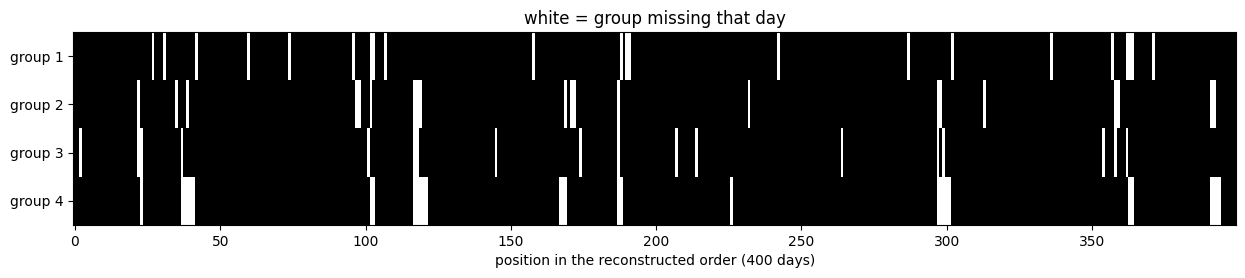

short holes (= holidays) in the biggest piece: 387


In [ ]:
P, M = cd.presence_matrix(X, pieces[0])

plt.figure(figsize=(15, 2.5))
plt.imshow(P[1000:1400].T, aspect="auto", cmap="Greys", interpolation="nearest")
plt.yticks(range(4), ["group 1", "group 2", "group 3", "group 4"])
plt.xlabel("position in the reconstructed order (400 days)")
plt.title("white = group missing that day")
plt.show()

print("short holes (= holidays) in the biggest piece:", int(((1 - P) * M).sum()))

## 4. Quelle bourse pour chaque groupe ?

On compare les groupes deux par deux avec toutes les paires de calendriers, puis on garde la meilleure combinaison.

In [ ]:
candidates = ["XNYS", "XTSE", "BVMF", "XLON", "XETR", "XPAR", "XSWX", "XJSE",
              "XTKS", "XHKG", "XKRX", "XSHG", "XTAI", "XSES", "XBOM", "XIDX",
              "XKLS", "XBKK", "XASX", "XNZE"]
sessions = cd.load_sessions(candidates)

exchanges, n_wrong = cd.find_exchanges(P, M, sessions)   # ~1 min
group_exchange = {g + 1: exchanges[g] for g in range(4)}
group_exchange

groups 1&2 (1511 days): best pair XTKS / XHKG


groups 1&3 (1505 days): best pair XTKS / XKRX


groups 1&4 (1505 days): best pair XTKS / XSHG


groups 2&3 (2000 days): best pair XHKG / XKRX


groups 2&4 (1944 days): best pair XHKG / XSHG


groups 3&4 (1961 days): best pair XKRX / XSHG
chosen: ['XTKS', 'XHKG', 'XKRX', 'XSHG'] -> 347 mismatches on the full pattern


{1: 'XTKS', 2: 'XHKG', 3: 'XKRX', 4: 'XSHG'}

## 5. Datation exacte des morceaux qui ont des jours fériés

On cale le motif sur le calendrier réel, puis une programmation dynamique corrige localement (jours absents des données).

In [ ]:
used_days = set()
dated_parts = []

for piece in pieces:
    P_piece, M_piece = cd.presence_matrix(X, piece)
    holes = int(((1 - P_piece) * M_piece).sum())
    if holes < 30:
        continue   # not enough holidays to be sure, we date it later with the returns

    out = cd.date_piece(X, piece, exchanges, sessions, used_days=used_days)
    out["method"] = "holidays"
    used_days |= set(out["date"].dropna())
    dated_parts.append(out)
    print(f"piece of {len(piece)} dates -> {out['date'].min().date()} to {out['date'].max().date()} | "
          f"{holes} holidays | {out['date'].isna().sum()} dates left without a day")

dated = pd.concat(dated_parts, ignore_index=True)

piece of 2099 dates -> 2007-09-26 to 2015-10-30 | 387 holidays | 6 dates left without a day


## 6. Vérification avec les indices

Si les dates sont bonnes, la moyenne de `RET_1` d'un groupe le jour d doit bouger avec l'indice de sa bourse **le jour d** (lag 0), et la `target` avec l'indice **le jour d+1** (lag 1). Aux autres décalages, la corrélation doit être proche de 0.

In [ ]:
index_of_exchange = {"XTKS": "NIKKEI225", "XHKG": "HSCEI", "XKRX": "KOSPI", "XSHG": "SHANGHAI",
                     "XNYS": "SP500", "XLON": "FTSE100", "XETR": "DAX", "XPAR": "CAC40", "XASX": "ASX200"}
group_index = {g: index_of_exchange[code] for g, code in group_exchange.items() if code in index_of_exchange}

cd.check_with_index(X, dated, index_returns, group_index, y=y).round(2)

lag                       -1     0     1
group index     column                  
1     NIKKEI225 RET_1  -0.11 -0.39 -0.03
                target -0.05 -0.12 -0.39
2     HSCEI     RET_1  -0.05 -0.32  0.02
                target -0.02 -0.03 -0.39
3     KOSPI     RET_1  -0.00 -0.16 -0.01
                target -0.08 -0.00 -0.16
4     SHANGHAI  RET_1   0.01 -0.53 -0.00
                target  0.03  0.01 -0.56

## 7. Les morceaux sans jours fériés : datation par les rendements

Souvent un seul groupe est présent, donc pas de motif. On apprend l'exposition de chaque allocation aux indices sur les dates déjà trouvées, puis on cherche où l'historique colle le mieux.

In [ ]:
betas = cd.fit_betas(X, dated, index_returns, sessions, group_exchange)
matcher = cd.ReturnMatcher(betas, index_returns, sessions, group_exchange)

for piece in pieces:
    if set(piece) & set(dated["TS"]):
        continue
    groups = [int(g) for g in sorted(X.loc[X["TS"].isin(piece), "GROUP"].unique())]
    days, _ = cd.union_calendar(sessions, [group_exchange[g] for g in groups])

    out = matcher.date_piece(X, piece, days, used_days=used_days)
    out["method"] = "returns"
    out["reliable"] = out["score"] > 2 * out["second_score"]
    used_days |= set(out["date"])
    dated = pd.concat([dated, out], ignore_index=True)
    print(f"piece of {len(piece)} dates (groups {groups}) -> {out['date'].min().date()} to {out['date'].max().date()} | "
          f"score {out['score'].iloc[0]:.4f} vs next best {out['second_score'].iloc[0]:.4f}")

piece of 180 dates (groups [3]) -> 2006-06-09 to 2007-02-28 | score 0.0998 vs next best 0.0127


piece of 73 dates (groups [3]) -> 2016-11-07 to 2017-02-20 | score 0.0024 vs next best 0.0023


piece of 63 dates (groups [3]) -> 2007-06-15 to 2007-09-13 | score 0.0254 vs next best 0.0065


piece of 57 dates (groups [3]) -> 2021-04-21 to 2021-07-12 | score 0.0121 vs next best 0.0119


piece of 30 dates (groups [3]) -> 2007-03-22 to 2007-05-03 | score 0.0084 vs next best 0.0061
piece of 10 dates (groups [3]) -> 2005-10-25 to 2005-11-07 | score 0.0057 vs next best 0.0046


piece of 5 dates (groups [3]) -> 2024-01-18 to 2024-01-24 | score 0.0022 vs next best 0.0021
piece of 4 dates (groups [3]) -> 2005-10-18 to 2005-10-21 | score 0.0034 vs next best 0.0033
piece of 1 dates (groups [3]) -> 2023-10-26 to 2023-10-26 | score 0.0009 vs next best 0.0008


In [ ]:
dated["reliable"] = dated["reliable"].fillna(True)    # holiday-dated pieces are reliable
dated.to_csv("calendar/train_dates.csv", index=False)

print(dated["method"].value_counts())
print("reliable dates:", int(dated["reliable"].sum()), "/", len(dated))
dated.sort_values("date").head()

method
holidays    2099
returns      423
Name: count, dtype: int64
reliable dates: 2342 / 2522


,TS,date,piece_size,holes_used,best_mismatch,second_mismatch,method,score,second_score,reliable
2517,DATE_0170,2005-10-18,4,NaN,NaN,NaN,returns,0.003450,0.003320,False
2518,DATE_1988,2005-10-19,4,NaN,NaN,NaN,returns,0.003450,0.003320,False
2519,DATE_0041,2005-10-20,4,NaN,NaN,NaN,returns,0.003450,0.003320,False
2520,DATE_1791,2005-10-21,4,NaN,NaN,NaN,returns,0.003450,0.003320,False
2502,DATE_2358,2005-10-25,10,NaN,NaN,NaN,returns,0.005737,0.004615,False


## 8. Et le test ?

Les dates du test n'ont aucun lien (ni avec le train, ni entre elles) : il ne reste que les rendements, une date à la fois.
D'abord, on mesure honnêtement la fiabilité : expositions apprises avant 2013, puis on essaie de retrouver des jours du train après 2013 comme s'ils étaient isolés.

In [ ]:
known = dated[dated["method"] == "holidays"].dropna(subset=["date"])
before = known[known["date"] < "2013-01-01"]
after = known[known["date"] >= "2013-01-01"].sample(150, random_state=0)

check_matcher = cd.ReturnMatcher(cd.fit_betas(X, before, index_returns, sessions, group_exchange),
                                 index_returns, sessions, group_exchange)
guess = cd.date_isolated(X[X["TS"].isin(after["TS"])], check_matcher)
guess = guess.merge(after[["TS", "date"]].rename(columns={"date": "true_date"}), on="TS")
guess["correct"] = guess["date"] == guess["true_date"]

print(f"exact day found for {guess['correct'].mean():.0%} of the isolated days")
for q in [0.5, 0.75]:
    th = guess["margin"].quantile(q)
    print(f"  when the margin is in the top {100 - int(q * 100)}%: {guess.loc[guess['margin'] > th, 'correct'].mean():.0%} correct")

exact day found for 25% of the isolated days
  when the margin is in the top 50%: 35% correct
  when the margin is in the top 25%: 47% correct


In [ ]:
test_dates = cd.date_isolated(X_test, matcher, excluded_days=used_days)
test_dates.to_csv("calendar/test_dates.csv", index=False)

print(test_dates["date"].dt.year.value_counts().sort_index())
test_dates.sort_values("margin", ascending=False).head(10)

date
2004     1
2006     2
2016    14
2017     9
2018    14
2019     6
2020     5
2021    12
2022    15
2023    16
2024    11
2025    12
2026     3
Name: count, dtype: int64


,TS,date,score,margin,second_date
74,DATE_2597,2020-03-17,0.014638,0.009280,2020-03-04
105,DATE_2628,2022-03-24,0.015123,0.009206,2024-02-01
25,DATE_2548,2024-08-26,0.010966,0.006405,2006-03-10
35,DATE_2558,2025-04-18,0.013372,0.005569,2024-08-19
73,DATE_2596,2018-10-30,0.012734,0.004980,2004-05-12
75,DATE_2598,2024-08-23,0.014762,0.004764,2025-04-24
23,DATE_2546,2016-01-04,0.006813,0.003845,2023-10-11
80,DATE_2603,2018-12-27,0.008314,0.003455,2016-05-09
65,DATE_2588,2022-02-23,0.005411,0.002989,2023-05-22
71,DATE_2594,2022-05-23,0.006300,0.002938,2026-04-09
